In [8]:
import importlib
from collections.abc import Iterator
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

import motion_estimation as me

importlib.reload(me)

from motion_estimation.cli import run
from motion_estimation.flow import DISConfig, FarnebackConfig, dis
from motion_estimation.pipeline import process_video
from motion_estimation.types import BGR2RGB, BGRImage
from motion_estimation.video import BGR_to_grayscale, read_video
from motion_estimation.visualization import draw_flow_vectors


In [9]:
def showBGR(image: BGRImage):
    return plt.imshow(BGR2RGB(image))

In [10]:
def skip(iterator: Iterator, n: int) -> None:
    for _ in range(n):
        next(iterator)

In [15]:
video_names = [
    "earth_30s.mp4",
    "Jellyfish_360_10s_1MB.mp4",
    "Big_Buck_Bunny_360_10s_1MB.mp4",
    "Sintel_360_10s_1MB.mp4",
]
video_paths = [Path(f"../data/{name}") for name in video_names]
video_path = video_paths[3]


In [16]:
video = read_video(video_path)

skip(video, 6)

first = next(video)
second = next(video)


flow = dis(BGR_to_grayscale(first), BGR_to_grayscale(second), DISConfig())

video.close()

[mov,mp4,m4a,3gp,3g2,mj2 @ 0x7bd2000] Referenced QT chapter track not found


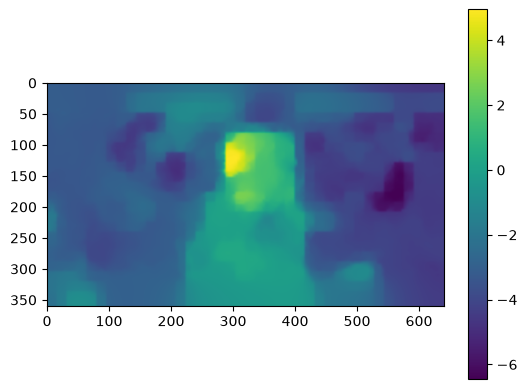

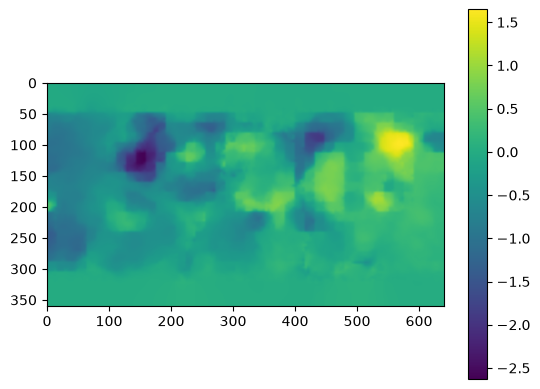

In [17]:
plt.imshow(flow[:,:,0])
plt.colorbar()
plt.show()
plt.imshow(flow[:,:,1])
plt.colorbar()
plt.show()

In [18]:
# run(video_paths[1])